# 03 · Red convolucional (CNN)

Fase CRISP-DM: **Modelado**.

A diferencia de los modelos clásicos, la CNN **sí ve la imagen**: el recorte de 128×128 con el fondo en negro. Es una red pequeña hecha desde cero (no usa modelos preentrenados como EfficientNet o ResNet).

**Arquitectura** (`src/models/model_definitions.py`): 4 bloques iguales `Conv 3×3 → BatchNorm → ReLU → MaxPool`. Los filtros se duplican en cada bloque (32, 64, 128, 256) mientras la imagen se reduce a la mitad (128 → 64 → 32 → 16 → 8). Después, `GlobalAveragePooling` (un número por filtro), `Dropout 0.35` y una capa de salida con 3 probabilidades (good, regular, bad).

**Entrenamiento** (`src/training/train_models.py`):
- Adam con tasa 0,001; se divide entre 2 si la pérdida no mejora en 4 épocas.
- Hasta 100 épocas; se detiene si la pérdida no mejora en 12 y se queda con la mejor época.
- Para decidir cuándo parar se aparta el **10 % de los grupos de train**. Val no se usa para nada durante el entrenamiento.
- Las clases con menos fotos (regular) pesan más en la pérdida (`class_weight="balanced"`).

Para entrenar (mejor con GPU):
```
python -m src.main entrenar --solo cnn
```

In [1]:
from pathlib import Path
import json
import sys

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src" / "config.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import pandas as pd

from src import config

def read(name):
    """Lee un resultado de results/; si no existe, explica qué comando lo genera."""
    path = config.RESULTS / name
    if not path.is_file():
        raise FileNotFoundError(f"Falta {path}. Corre primero los pasos del README.")
    return json.loads(path.read_text(encoding="utf-8"))

config.FIGURES.mkdir(parents=True, exist_ok=True)

## Las capas y sus parámetros (necesita TensorFlow)

In [2]:
from src.models.model_definitions import CNN_SETTINGS, build_cnn
from src.training.train_models import tensorflow

build_cnn(tensorflow()).summary()
CNN_SETTINGS

Model: "cnn_calidad"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,627 (1.49 MB)

 Trainable params: 389,667 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

{'filters_per_block': (32, 64, 128, 256),
 'dropout': 0.35,
 'learning_rate': 0.001,
 'batch_size': 64,
 'max_epochs': 100,
 'patience': 12,
 'reduce_lr_patience': 4,
 'min_lr': 1e-05,
 'early_stop_fraction': 0.1}

## Curvas de aprendizaje

`loss` es la pérdida en las fotos con que se ajustan los pesos; `val_loss` es la del 10 % de grupos apartado de train (Keras lo llama "validation", pero **no** es la partición val). Si `loss` sigue bajando y `val_loss` sube, la red empieza a memorizar: ahí la parada temprana la detiene.

Mejor época: 18 de 30 · 389,667 parámetros · 62 min


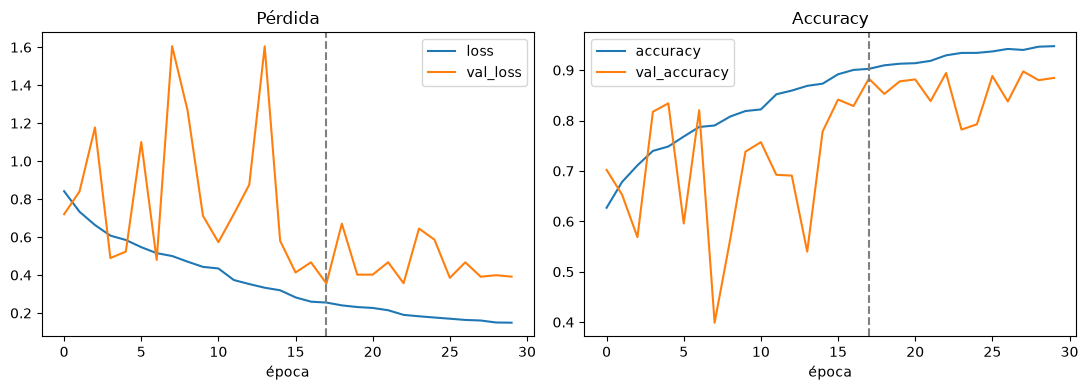

In [3]:
cnn = read("entrenamiento_cnn.json")
history = pd.DataFrame(cnn["history"])
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
history[["loss", "val_loss"]].plot(ax=left, title="Pérdida")
history[["accuracy", "val_accuracy"]].plot(ax=right, title="Accuracy")
for ax in (left, right):
    ax.axvline(cnn["best_epoch"] - 1, color="gray", linestyle="--")
    ax.set_xlabel("época")
fig.tight_layout()
fig.savefig(config.FIGURES / "cnn_curvas.png", dpi=150)
print(f"Mejor época: {cnn['best_epoch']} de {cnn['epochs_run']} · "
      f"{cnn['trainable_params']:,} parámetros · {cnn['seconds'] / 60:.0f} min")

## Resultado en val

In [4]:
val = cnn["validation"]
print(f"F1 macro {val['f1_macro']:.3f} · malas que pasaron como buenas: {val['bad_to_good']}")
pd.DataFrame(val["confusion_matrix"], index=[f"real {c}" for c in val["labels"]],
             columns=[f"predicho {c}" for c in val["labels"]])

F1 macro 0.738 · malas que pasaron como buenas: 120


,predicho good,predicho regular,predicho bad
real good,1367,149,36
real regular,448,400,69
real bad,120,19,997
